In [8]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Наложение и удаление шума

In [9]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

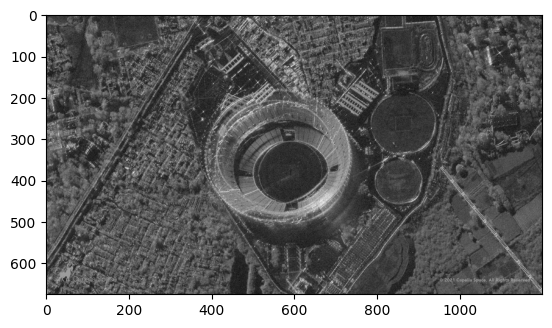

In [10]:
plt.imshow(image_gray, cmap="gray")

In [11]:
# Gaussian noise
mean = 0
stddev = 100
noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)

array([[  0,  16,   0, ..., 111,   0,  80],
       [  1, 104,  68, ...,   0, 103,   0],
       [  0,   0,  51, ...,   0,   0, 145],
       ...,
       [  0,   0,  39, ..., 255,   0,  15],
       [  0,  34,   0, ...,   0,   5, 135],
       [160, 204,   0, ...,  21,   0, 109]], dtype=uint8)

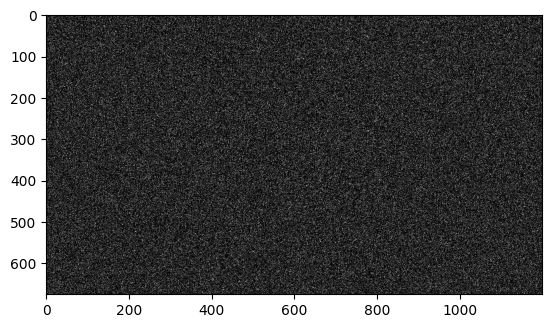

In [12]:
plt.imshow(noise_gauss, cmap="gray")

In [13]:
# Salt and pepper
noise =  np.random.randint(0, 101, size = (image_gray.shape[0], image_gray.shape[1]), dtype=int)
zeros_pixel = np.where(noise == 0)
ones_pixel = np.where(noise == 100)

In [14]:
bg_image = np.ones(image_gray.shape, np.uint8) * 128

In [15]:
bg_image[zeros_pixel] = 0
bg_image[ones_pixel] = 255

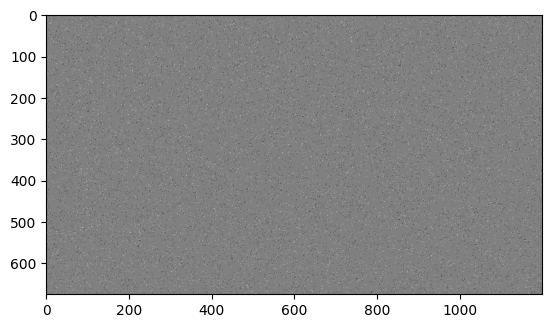

In [16]:
plt.imshow(bg_image, cmap="gray")

In [17]:
image_noise_gauss = cv2.add(image_gray,noise_gauss)

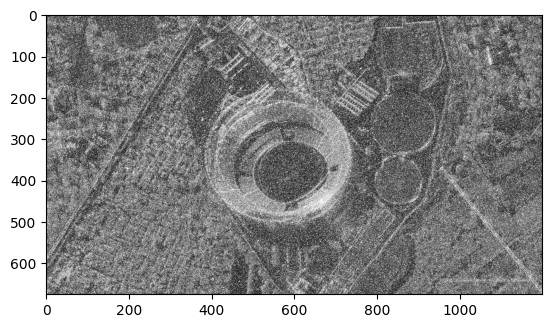

In [18]:
plt.imshow(image_noise_gauss, cmap="gray")

In [19]:
from skimage.metrics import structural_similarity, mean_squared_error
mse_gauss = mean_squared_error(image_gray, image_noise_gauss)
(ssim, diff) = structural_similarity(image_gray, image_noise_gauss, full=True)
print(mse_gauss, ssim)

4230.673058024691 0.1869926680003536


In [20]:
image_gauss_median = cv2.medianBlur(image_noise_gauss, 3)

In [21]:
mse_gauss_median = mean_squared_error(image_gray, image_gauss_median)
(ssim_gauss_median, diff) = structural_similarity(image_gray,  image_gauss_median, full=True)

In [22]:
print(mse_gauss_median, ssim_gauss_median)

1038.0453432098766 0.4282430571563417


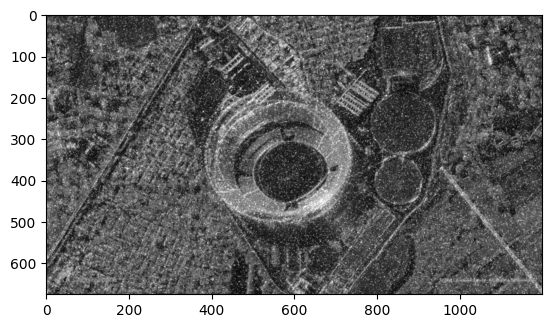

In [23]:
plt.imshow(image_gauss_median, cmap="gray")

In [24]:
import copy

image_sp = copy.deepcopy(image_gray)

image_sp[zeros_pixel] = 0
image_sp[ones_pixel] = 255

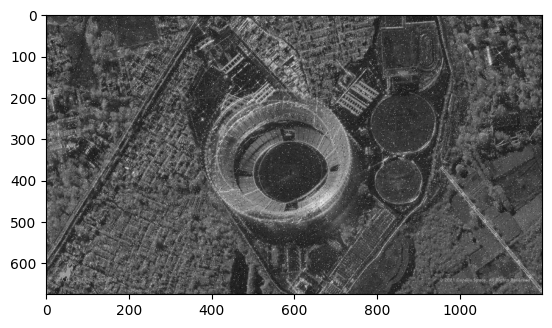

In [25]:
plt.imshow(image_sp, cmap="gray")

In [26]:
mse_sp = mean_squared_error(image_gray, image_sp)
(ssim_sp, diff) = structural_similarity(image_gray, image_sp, full=True)
print(mse_sp, ssim_sp)

390.6858765432099 0.7197444505561609


In [27]:
image_sp_median = cv2.medianBlur(image_sp, 3)

In [28]:
mse_sp_median = mean_squared_error(image_gray, image_sp_median)
(ssim_sp_median, diff) = structural_similarity(image_gray, image_sp_median, full=True)
print(mse_sp_median, ssim_sp_median)

95.88730370370371 0.8161634963949215


# Другие типы фильтров

In [29]:
image_gauss_gauss = cv2.GaussianBlur(image_noise_gauss,(5,5),0)

In [30]:
image_gauss_bilat = cv2.bilateralFilter(image_noise_gauss,9,75,75)

In [31]:
image_gauss_nlm = cv2.fastNlMeansDenoising(image_noise_gauss, h = 20)

In [32]:
import math

def geom(a):
    prod = 1
    for i in range(a.shape[0]):
        prod1 = 1
        for j in range(a.shape[1]):
            prod1 *= a[i,j]
        prod1 = math.pow(prod1, 1.0/9.0)
        prod *= prod1
    return prod

def proc(img, filter):
    img_res = copy.deepcopy(img)
    for i in range(0,img.shape[0] -2):
        for j in range(0,img.shape[1] -2):
            img_res[i:i+3, j:j+3] = filter(img[i:i+3, j:j+3])
    return img_res

res = proc(image_noise_gauss, geom)


/tmp/ipykernel_3532/3044326922.py:8: RuntimeWarning: overflow encountered in scalar multiply
  prod1 *= a[i,j]


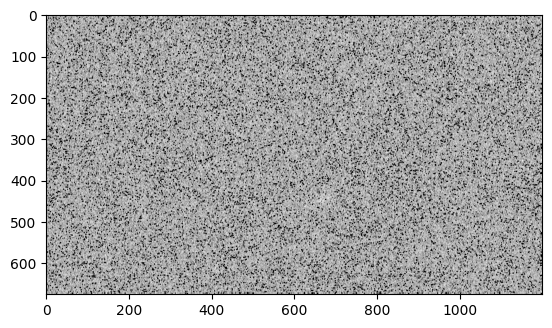

In [33]:
plt.imshow(res, cmap="gray")

In [34]:
mse_geom = mean_squared_error(image_gray, res)
(ssim_geom, diff) = structural_similarity(image_gray, res, full=True)
print(mse_geom, ssim_geom)

6551.976648148148 0.02746126776511091



# 2D свертка

In [35]:
# averaging filter
kernel_5 = np.ones((5,5),np.float32)/25
image_k5 = cv2.filter2D(image_gray,-1,kernel_5)
# blured_image = cv2.blur(img,(5,5))
image_b5 = cv2.blur(image_gray,(5,5))

In [36]:
mse_kb = mean_squared_error(image_k5, image_b5)
(ssim_kb, diff) = structural_similarity(image_k5, image_b5, full=True)
print(mse_kb, ssim_kb)

0.0 1.0


In [37]:
# Laplasian
kernel_lapl = np.array([[0,-10,0],
                        [-10,40,-10],
                        [0,-10,0]], np.float32)

In [38]:
image_lapl = cv2.filter2D(image_gray,-1,kernel_lapl)

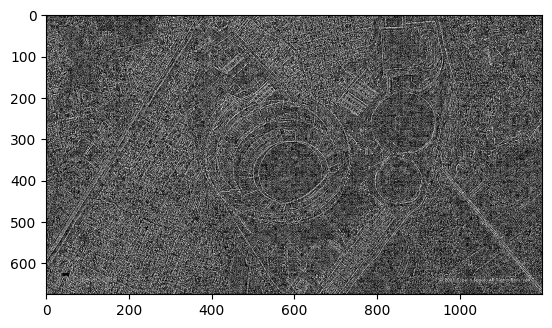

In [39]:
plt.imshow(image_lapl, cmap="gray")

In [40]:
# ДЗ 2
# Зашумить изображение при помощи шума гаусса, постоянного шума.
# Протестировать медианный фильтр, фильтр гаусса, билатериальный фильтр, фильтр нелокальных средних с различными параметрами.
# Выяснить, какой фильтр показал лучший результат фильтрации шума.

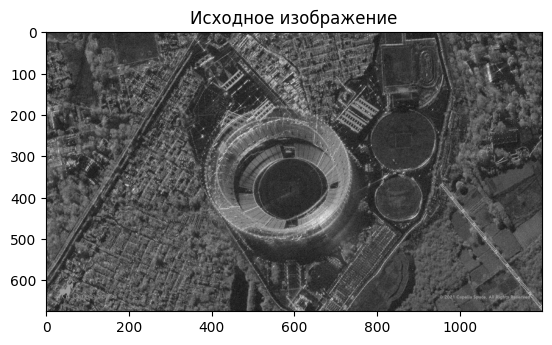

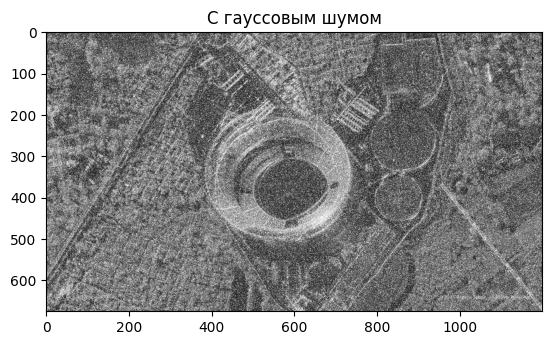

Гауссов шум: MSE = 4226.025272839506  SSIM = 0.18728917567733971


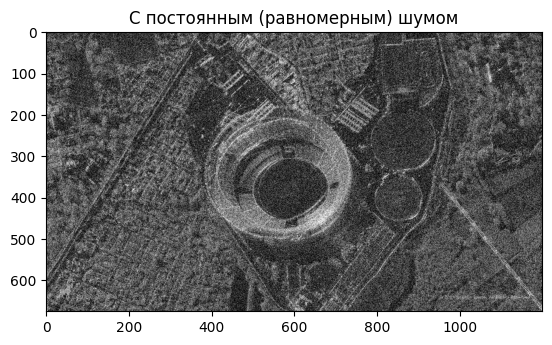

Постоянный шум: MSE = 1948.4200234567902  SSIM = 0.24518702492588676


In [41]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray, cmap="gray")
plt.title('Исходное изображение')
plt.show()

mean = 0
stddev = 100
noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)

image_noise_gauss = cv2.add(image_gray, noise_gauss)

plt.imshow(image_noise_gauss, cmap="gray")
plt.title('С гауссовым шумом')
plt.show()

mse_gauss = mean_squared_error(image_gray, image_noise_gauss)
(ssim_gauss, diff) = structural_similarity(image_gray, image_noise_gauss, full=True)
print('Гауссов шум: MSE =', mse_gauss, ' SSIM =', ssim_gauss)

noise_const = np.random.uniform(-80, 80, image_gray.shape).astype(np.int16)
image_const = image_gray.astype(np.int16) + noise_const
image_const = np.clip(image_const, 0, 255).astype(np.uint8)

plt.imshow(image_const, cmap="gray")
plt.title('С постоянным (равномерным) шумом')
plt.show()

mse_const = mean_squared_error(image_gray, image_const)
(ssim_const, diff) = structural_similarity(image_gray, image_const, full=True)
print('Постоянный шум: MSE =', mse_const, ' SSIM =', ssim_const)

Медианный, постоянный шум: MSE = 640.0879283950617  SSIM = 0.38716841618003545


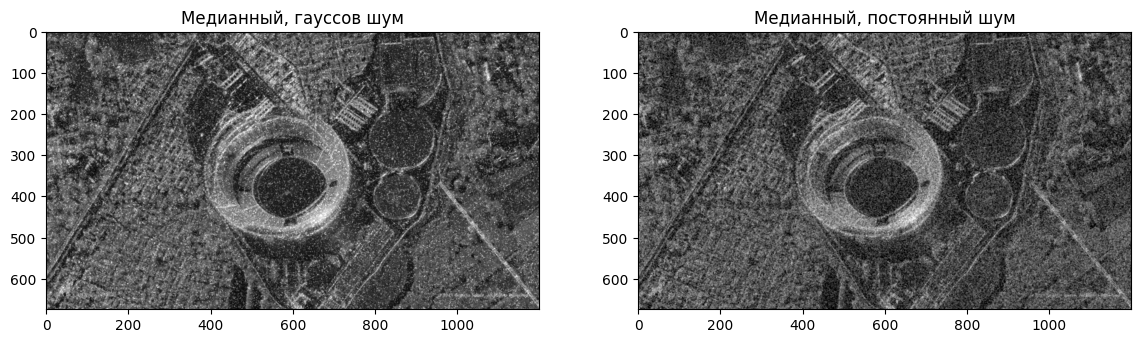

Гаусс(3x3), постоянный шум : MSE = 346.76634074074076  SSIM = 0.5380783366107524
Гаусс(5x5), постоянный шум : MSE = 265.2054024691358  SSIM = 0.57829878007328


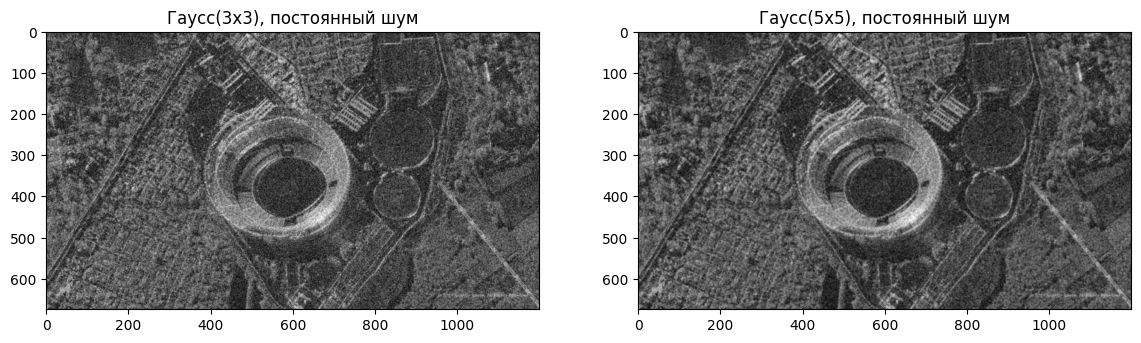

In [46]:
image_const_median = cv2.medianBlur(image_const, 3)

mse_const_median = mean_squared_error(image_gray, image_const_median)
(ssim_const_median, diff) = structural_similarity(image_gray, image_const_median, full=True)
print('Медианный, постоянный шум: MSE =', mse_const_median, ' SSIM =', ssim_const_median)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(image_gauss_median, cmap="gray"); ax[0].set_title('Медианный, гауссов шум')
ax[1].imshow(image_const_median, cmap="gray"); ax[1].set_title('Медианный, постоянный шум')
plt.show()

image_const_gauss3 = cv2.GaussianBlur(image_const, (3,3), 0)
image_const_gauss5 = cv2.GaussianBlur(image_const, (5,5), 0)

for name, im in [('Гаусс(3x3), постоянный шум', image_const_gauss3),
                  ('Гаусс(5x5), постоянный шум', image_const_gauss5)]:
    mse = mean_squared_error(image_gray, im)
    (ssim, diff) = structural_similarity(image_gray, im, full=True)
    print(name, ': MSE =', mse, ' SSIM =', ssim)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(image_const_gauss3, cmap="gray"); ax[0].set_title('Гаусс(3x3), постоянный шум')
ax[1].imshow(image_const_gauss5, cmap="gray"); ax[1].set_title('Гаусс(5x5), постоянный шум')
plt.show()

Билатеральный(75,75), гауссов шум : MSE = 1835.839639506173  SSIM = 0.31506140403628613
Билатеральный(25,25), гауссов шум : MSE = 3779.118972839506  SSIM = 0.1817579786316534
Билатеральный(75,75), Постоянный шум : MSE = 375.14084814814817  SSIM = 0.47650985009134345
Билатеральный(25,25), Постоянный шум : MSE = 1441.3625086419754  SSIM = 0.2755192066584676


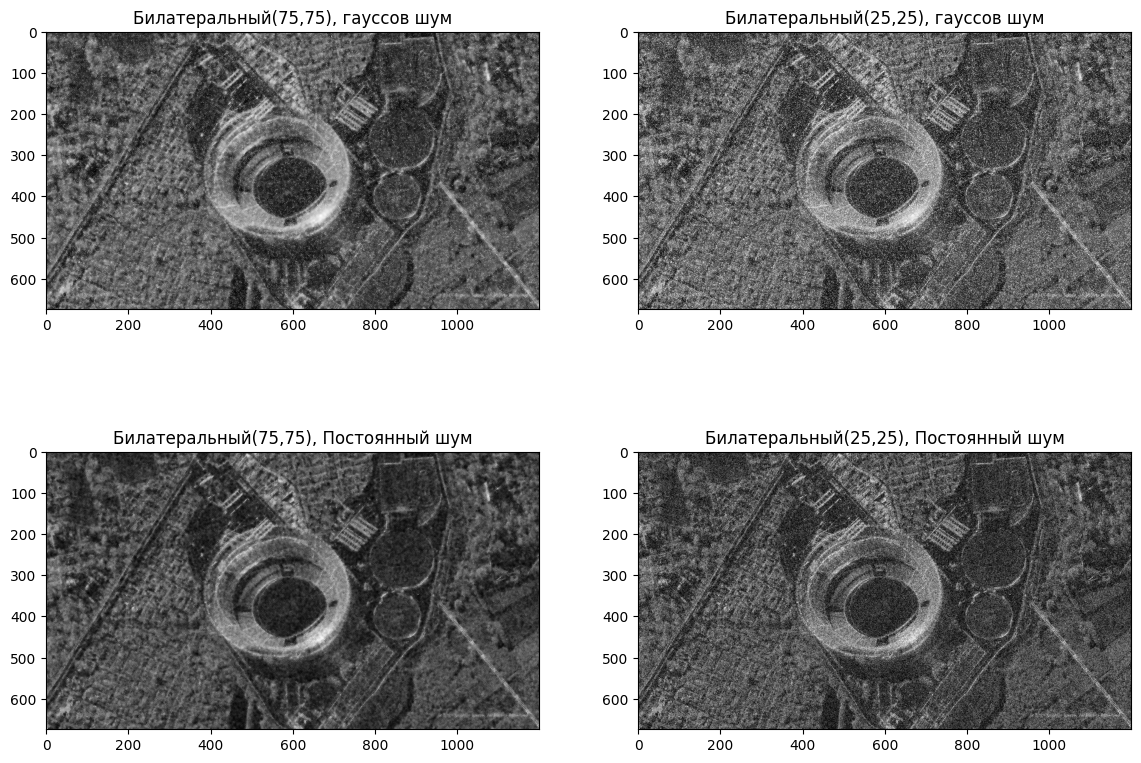

NLM(h=10), гауссов шум : MSE = 4226.022839506173  SSIM = 0.18729040059573604
NLM(h=20), гауссов шум : MSE = 4221.6409370370375  SSIM = 0.18772865263575678
NLM(h=10), Постоянный шум : MSE = 1948.4200234567902  SSIM = 0.24518702492588676
NLM(h=20), Постоянный шум : MSE = 1909.1841555555557  SSIM = 0.2472348314333486


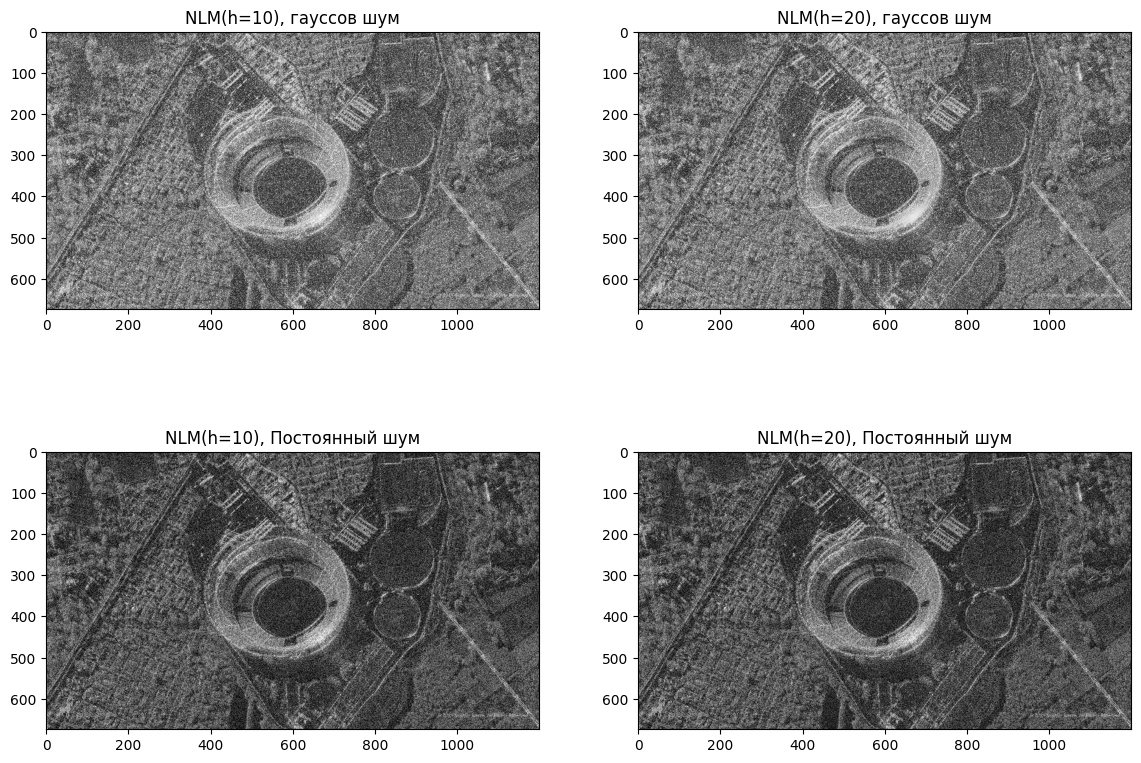

In [47]:
image_gauss_bilat1 = cv2.bilateralFilter(image_noise_gauss, 9, 75, 75)
image_gauss_bilat2 = cv2.bilateralFilter(image_noise_gauss, 9, 25, 25)
image_const_bilat1 = cv2.bilateralFilter(image_const, 9, 75, 75)
image_const_bilat2 = cv2.bilateralFilter(image_const, 9, 25, 25)

for name, im in [('Билатеральный(75,75), гауссов шум', image_gauss_bilat1),
                  ('Билатеральный(25,25), гауссов шум', image_gauss_bilat2),
                  ('Билатеральный(75,75), Постоянный шум', image_const_bilat1),
                  ('Билатеральный(25,25), Постоянный шум', image_const_bilat2)]:
    mse = mean_squared_error(image_gray, im)
    (ssim, diff) = structural_similarity(image_gray, im, full=True)
    print(name, ': MSE =', mse, ' SSIM =', ssim)

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
ax[0,0].imshow(image_gauss_bilat1, cmap="gray"); ax[0,0].set_title('Билатеральный(75,75), гауссов шум')
ax[0,1].imshow(image_gauss_bilat2, cmap="gray"); ax[0,1].set_title('Билатеральный(25,25), гауссов шум')
ax[1,0].imshow(image_const_bilat1, cmap="gray"); ax[1,0].set_title('Билатеральный(75,75), Постоянный шум')
ax[1,1].imshow(image_const_bilat2, cmap="gray"); ax[1,1].set_title('Билатеральный(25,25), Постоянный шум')
plt.show()

image_gauss_nlm10 = cv2.fastNlMeansDenoising(image_noise_gauss, h=10)
image_gauss_nlm20 = cv2.fastNlMeansDenoising(image_noise_gauss, h=20)
image_const_nlm10 = cv2.fastNlMeansDenoising(image_const, h=10)
image_const_nlm20 = cv2.fastNlMeansDenoising(image_const, h=20)

for name, im in [('NLM(h=10), гауссов шум', image_gauss_nlm10),
                  ('NLM(h=20), гауссов шум', image_gauss_nlm20),
                  ('NLM(h=10), Постоянный шум', image_const_nlm10),
                  ('NLM(h=20), Постоянный шум', image_const_nlm20)]:
    mse = mean_squared_error(image_gray, im)
    (ssim, diff) = structural_similarity(image_gray, im, full=True)
    print(name, ': MSE =', mse, ' SSIM =', ssim)

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
ax[0,0].imshow(image_gauss_nlm10, cmap="gray"); ax[0,0].set_title('NLM(h=10), гауссов шум')
ax[0,1].imshow(image_gauss_nlm20, cmap="gray"); ax[0,1].set_title('NLM(h=20), гауссов шум')
ax[1,0].imshow(image_const_nlm10, cmap="gray"); ax[1,0].set_title('NLM(h=10), Постоянный шум')
ax[1,1].imshow(image_const_nlm20, cmap="gray"); ax[1,1].set_title('NLM(h=20), Постоянный шум')
plt.show()

NLM(h=60), Постоянный шум : MSE = 408.79266913580244  SSIM = 0.35667381239227797
NLM(h=100), Постоянный шум : MSE = 471.40706666666665  SSIM = 0.2971598457210883


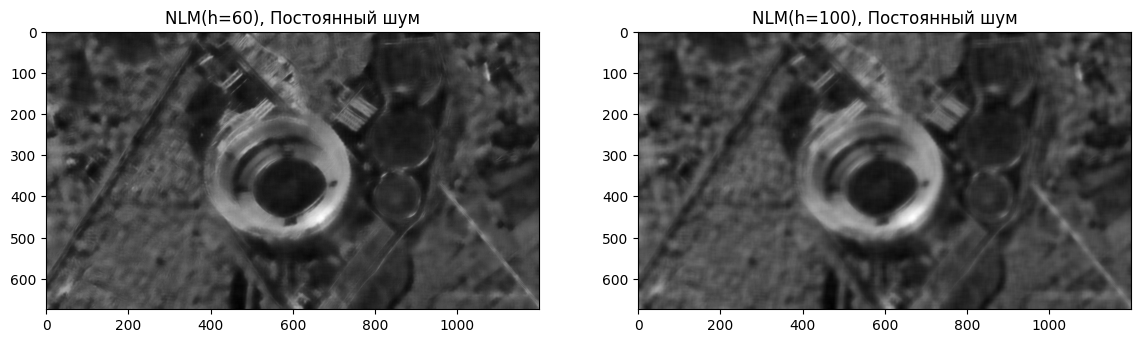

In [49]:
image_const_nlm60 = cv2.fastNlMeansDenoising(image_const, h=60)
image_const_nlm100 = cv2.fastNlMeansDenoising(image_const, h=100)

for name, im in [('NLM(h=60), Постоянный шум', image_const_nlm60),
                  ('NLM(h=100), Постоянный шум', image_const_nlm100)]:
    mse = mean_squared_error(image_gray, im)
    (ssim, diff) = structural_similarity(image_gray, im, full=True)
    print(name, ': MSE =', mse, ' SSIM =', ssim)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(image_const_nlm60, cmap="gray"); ax[0].set_title('NLM(h=60), Постоянный шум')
ax[1].imshow(image_const_nlm100, cmap="gray"); ax[1].set_title('NLM(h=100), Постоянный шум')
plt.show()

In [50]:
import pandas as pd

results = [
    ('Без фильтра', 'Гауссов шум', '-', 4226.03, 0.1873),
    ('Без фильтра', 'Постоянный шум', '-', 1948.42, 0.2452),
    ('Медианный', 'Гауссов шум', '3x3', 1035.58, 0.4294),
    ('Медианный', 'Постоянный шум', '3x3', 640.09, 0.3872),
    ('Гаусс', 'Гауссов шум', '3x3', 1900.51, 0.4409),
    ('Гаусс', 'Гауссов шум', '5x5', 1761.81, 0.4866),
    ('Гаусс', 'Постоянный шум', '3x3', 346.77, 0.5381),
    ('Гаусс', 'Постоянный шум', '5x5', 265.21, 0.5783),
    ('Билатеральный', 'Гауссов шум', 'sigma=75', 1835.84, 0.3151),
    ('Билатеральный', 'Гауссов шум', 'sigma=25', 3779.12, 0.1818),
    ('Билатеральный', 'Постоянный шум', 'sigma=75', 375.14, 0.4765),
    ('Билатеральный', 'Постоянный шум', 'sigma=25', 1441.36, 0.2755),
    ('NLM', 'Гауссов шум', 'h=10', 4226.02, 0.1873),
    ('NLM', 'Гауссов шум', 'h=20', 4221.64, 0.1877),
    ('NLM', 'Гауссов шум', 'h=60', 1799.25, 0.3293),
    ('NLM', 'Гауссов шум', 'h=100', 1886.27, 0.2702),
    ('NLM', 'Постоянный шум', 'h=10', 1948.42, 0.2452),
    ('NLM', 'Постоянный шум', 'h=20', 1909.18, 0.2472),
    ('NLM', 'Постоянный шум', 'h=60', 408.79, 0.3567),
    ('NLM', 'Постоянный шум', 'h=100', 471.41, 0.2972),
]

df = pd.DataFrame(results, columns=['Фильтр', 'Шум', 'Параметры', 'MSE', 'SSIM'])

print('=== Гауссов шум, по возрастанию MSE ===')
print(df[df['Шум'] == 'Гауссов шум'].sort_values('MSE').to_string(index=False))
print()
print('=== Постоянный шум, по возрастанию MSE ===')
print(df[df['Шум'] == 'Постоянный шум'].sort_values('MSE').to_string(index=False))

=== Гауссов шум, по возрастанию MSE ===
       Фильтр         Шум Параметры     MSE   SSIM
    Медианный Гауссов шум       3x3 1035.58 0.4294
        Гаусс Гауссов шум       5x5 1761.81 0.4866
          NLM Гауссов шум      h=60 1799.25 0.3293
Билатеральный Гауссов шум  sigma=75 1835.84 0.3151
          NLM Гауссов шум     h=100 1886.27 0.2702
        Гаусс Гауссов шум       3x3 1900.51 0.4409
Билатеральный Гауссов шум  sigma=25 3779.12 0.1818
          NLM Гауссов шум      h=20 4221.64 0.1877
          NLM Гауссов шум      h=10 4226.02 0.1873
  Без фильтра Гауссов шум         - 4226.03 0.1873

=== Постоянный шум, по возрастанию MSE ===
       Фильтр            Шум Параметры     MSE   SSIM
        Гаусс Постоянный шум       5x5  265.21 0.5783
        Гаусс Постоянный шум       3x3  346.77 0.5381
Билатеральный Постоянный шум  sigma=75  375.14 0.4765
          NLM Постоянный шум      h=60  408.79 0.3567
          NLM Постоянный шум     h=100  471.41 0.2972
    Медианный Постоянный шум   

Лучший Гауссов шум по результатам  MSE - Медианный Гауссов шум

Лучший Гауссов шум по результатам  SSIM - Фильтр гаусса 5x5

Лучший Постоянный шум по MSE(и SSIM) - Гаусс 5x5
